# P6 — Operasi Morfologi dan Komponen Terhubung (Bagian 3, 4, 5)
Nama: Prima Pratama Putra · NIM 2330511022 · Kelas 7A · **SEED = 1022**

Alur bercak: `praproses` → `mask_daun_awal` (Otsu kanal S) → `bercak_awal` (kanal R, median + k·MAD) → **bersihkan** (opening, closing) → **ukur dan saring** (luas, kebulatan, rasio aspek) → persen bercak dan kelas mutu.

## Persiapan (Kode 1.1 dan fungsi tepi dari P5)

In [1]:
import sys, json, time
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")
URUT = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

def simpan(nama):
    plt.savefig(f"../hasil/{nama}", dpi=120, bbox_inches="tight")

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

def canny_persentil(g, q, rasio=0.4, sigma=2.0):        # dari P5 Langkah 2.4
    gb = cv2.GaussianBlur(g, (0, 0), sigma) if sigma > 0 else g
    gf = gb.astype(np.float32)
    mag = np.hypot(cv2.Sobel(gf, cv2.CV_32F, 1, 0), cv2.Sobel(gf, cv2.CV_32F, 0, 1))
    hi = float(np.percentile(mag, q))
    return cv2.Canny(gb, rasio * hi, hi, L2gradient=True)

# praproses semua citra sekali saja, dipakai ulang di seluruh notebook
PRA = {d.nama_file: praproses(muat(d.nama_file)[0], PARAM) for _, d in label.iterrows()}
print(len(PRA), "citra sudah dipraproses")

60 citra sudah dipraproses


## Bagian 3. Operasi Morfologi pada Citra Biner
### Langkah 3.1 Lembar hitung manual (dicek dengan kode)
SE persegi 3 × 3, piksel di luar citra bernilai 0 (`borderValue=0`).

In [2]:
B = np.array([[0,0,0,0,0,0,0,0,0],
              [0,1,1,1,0,0,0,0,0],
              [0,1,0,1,0,0,0,1,0],
              [0,1,1,1,0,0,0,0,0],
              [0,0,0,0,1,0,0,0,0],
              [0,0,0,0,0,0,0,0,0],
              [0,0,0,0,0,0,0,0,0],
              [0,1,1,1,1,1,1,0,0],
              [0,0,0,0,0,0,0,0,0]], np.uint8)
K3 = np.ones((3, 3), np.uint8)
kw = dict(borderType=cv2.BORDER_CONSTANT, borderValue=0)
erosi_B = cv2.erode(B, K3, **kw)
opening_B = cv2.dilate(erosi_B, K3, **kw)
closing_B = cv2.erode(cv2.dilate(B, K3, **kw), K3, **kw)
close_open_B = cv2.dilate(cv2.erode(closing_B, K3, **kw), K3, **kw)

for konek in [4, 8]:
    print(f"a) komponen konektivitas {konek}: {cv2.connectedComponents(B, connectivity=konek)[0] - 1}")
for nm, M in [("b) erosi", erosi_B), ("b) opening", opening_B), ("c) closing", closing_B), ("d) closing lalu opening", close_open_B)]:
    print(f"\n{nm} (jumlah piksel {int(M.sum())}, komponen-8 {cv2.connectedComponents(M, connectivity=8)[0] - 1}):")
    print(M)

a) komponen konektivitas 4: 4
a) komponen konektivitas 8: 3

b) erosi (jumlah piksel 0, komponen-8 0):
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]

b) opening (jumlah piksel 0, komponen-8 0):
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]

c) closing (jumlah piksel 19, komponen-8 2):
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 1 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 0 0 0 0]]

d) closing lalu opening (jumlah piksel 9, komponen-8 1):
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 

Sama dengan hitungan tangan:
- (a) Konektivitas 4 memberi 4 komponen, konektivitas 8 memberi 3. Piksel diagonal (4,4) menyatu dengan bercak bila memakai konektivitas 8.
- (b) Erosi dan opening mengosongkan citra. Tidak ada satu pun piksel yang seluruh tetangga 3 × 3-nya bernilai 1, karena bercak berlubang di tengah dan garis hanya setebal 1 piksel.
- (c) Closing menutup lubang bercak, tetapi juga mengisi celah antara piksel diagonal dan garis: (5,4) dan (6,4) menjadi 1. Bercak, piksel diagonal, dan garis menyatu menjadi satu komponen, sedangkan titik derau tetap ada.
- (d) Closing lalu opening hanya menyisakan bercak 3 × 3 yang utuh (9 piksel).

### Langkah 3.2 Citra biner awal
**Kode 3.1** Mask daun awal dan bercak awal

         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.998                   150               7           0.489
1  teh_021.png          0.999                   127               3           0.269
2  teh_011.png          0.996                   238               0               -


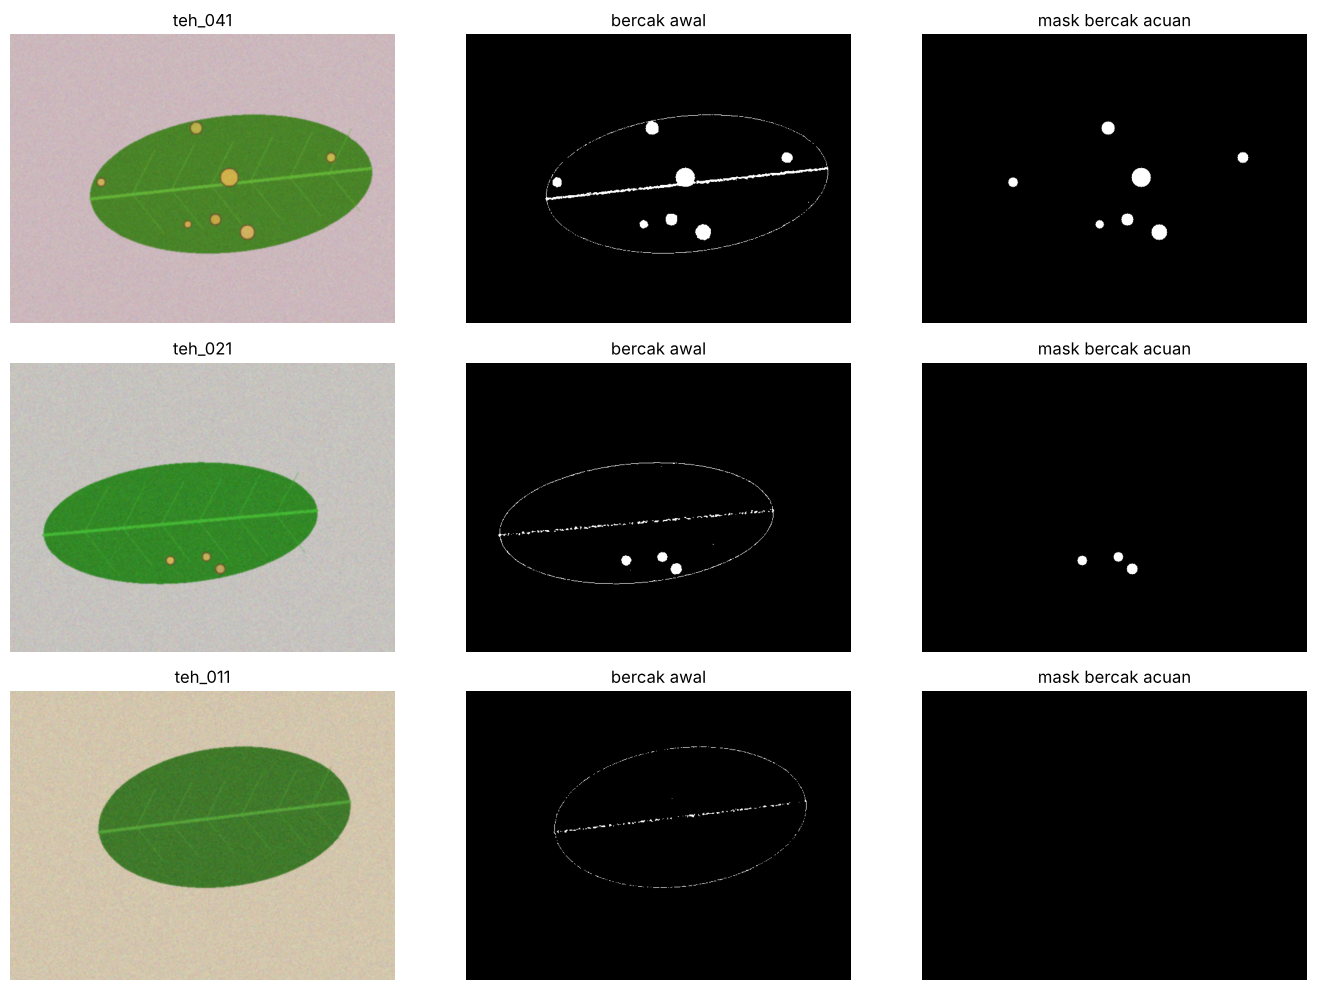

In [3]:
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:     # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)
    baris.append([nama, round(iou(m_daun, md), 3), jumlah_komponen(b0), jumlah_komponen(mb),
                  round(iou(b0, mb), 3) if mb.any() else "-"])
    panel += [pra_, b0, mb]; judul += [nama[:7], "bercak awal", "mask bercak acuan"]
print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal",
                                   "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))
simpan("p6_bercak_awal.png"); plt.show()

### Langkah 3.3 Enam operasi
**Kode 3.2** Erosi, dilasi, opening, dan closing (SE elips 5 × 5)

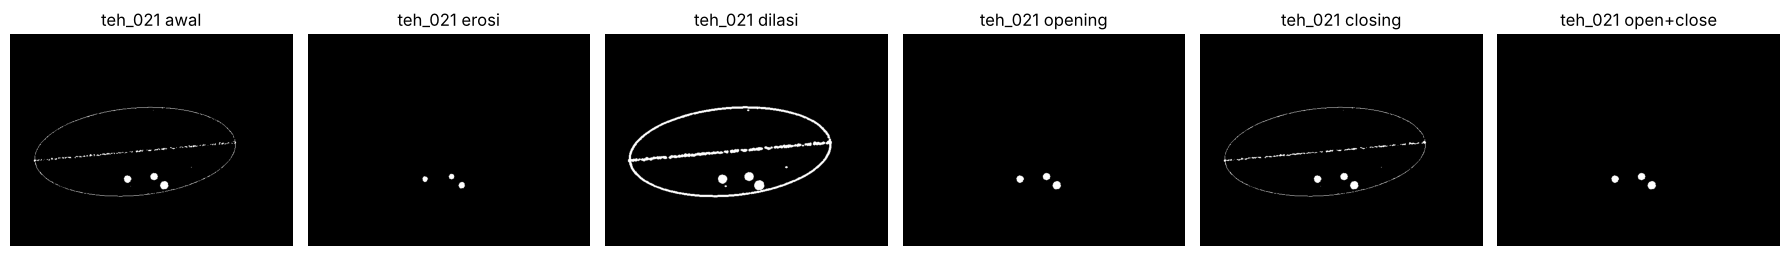

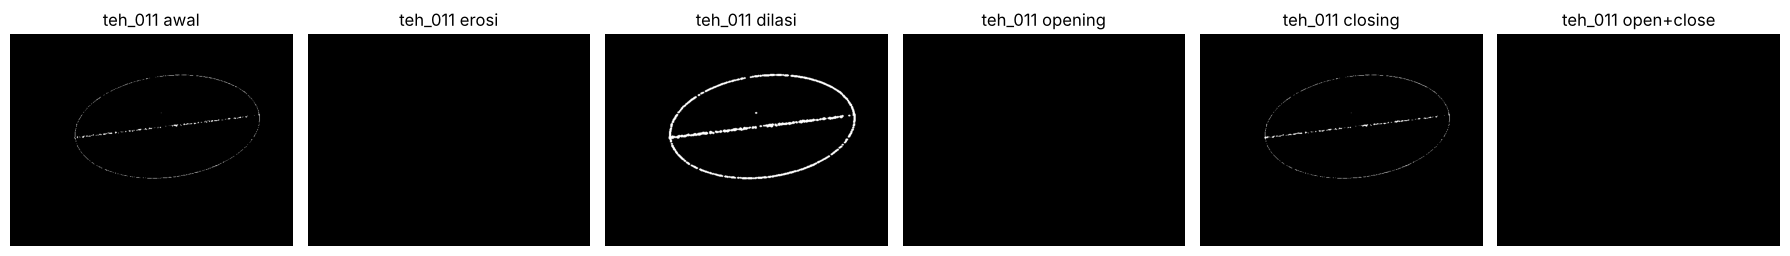

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       127    2394  0.269
1   teh_021.png       erosi         3     399  0.617
2   teh_021.png      dilasi        16    8984  0.072
3   teh_021.png     opening         3     696  0.921
4   teh_021.png     closing        79    2591  0.248
5   teh_021.png  open+close         3     696  0.921
6   teh_011.png        awal       238    1101      -
7   teh_011.png       erosi         0       0      -
8   teh_011.png      dilasi        25    6611      -
9   teh_011.png     opening         0       0      -
10  teh_011.png     closing       208    1205      -
11  teh_011.png  open+close         0       0      -


In [4]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m_ in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m_), int((m_ > 0).sum()),
                      round(iou(m_, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), [f"{nama[:7]} {k}" for k in hasil], ukuran=(18, 3))
    simpan(f"p6_operasi_{nama[:7]}.png"); plt.show()
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]))

**Bukti P3.3: mengapa potongan tulang daun tersisa setelah opening?** Opening dengan SE elips 5 hanya membuang bagian yang tidak dapat memuat SE itu, yaitu yang lebih sempit dari ±5 piksel. Untuk 20 daun sehat, tebal setiap komponen sebelum dan sesudah opening diukur dengan distance transform (tebal maksimum = 2 × jarak terbesar ke latar), lalu dicatat letaknya: di sepanjang tulang daun utama atau di tepi daun.

          citra         kondisi  komponen_awal  komponen_sesudah_opening  piksel_sisa  persen_sisa_di_tepi_daun  tebal_maks_sisa  tebal_median_awal
0   teh_001.png          normal            166                        29         1038                       4.1              6.0                2.0
1   teh_002.png           gelap            153                         0            0                       0.0              0.0                2.0
2   teh_003.png          terang            246                         0            0                       0.0              0.0                2.0
3   teh_004.png  kontras_rendah            589                         0            0                       0.0              0.0                2.0
4   teh_005.png        bayangan            124                         1           26                       0.0              4.4                2.0
5   teh_006.png          normal             81                         7         1736                       2.1 

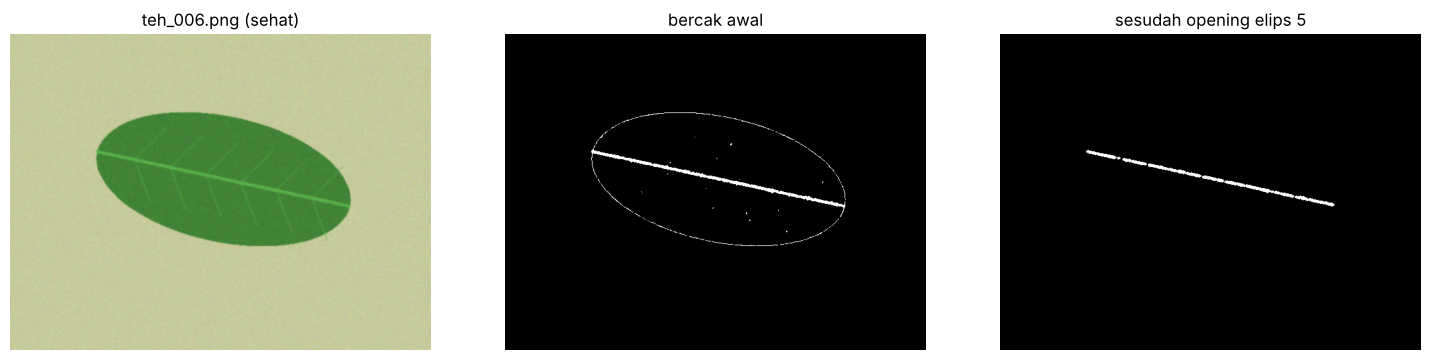

In [5]:
def tebal_komponen(m_):
    n, lbl, st, _ = cv2.connectedComponentsWithStats((m_ > 0).astype(np.uint8))
    dt = cv2.distanceTransform((m_ > 0).astype(np.uint8), cv2.DIST_L2, 5)
    return [(int(st[i, cv2.CC_STAT_AREA]), 2 * float(dt[lbl == i].max())) for i in range(1, n)]

baris = []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file); pra_ = PRA[d.nama_file]; m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun)
    op = cv2.morphologyEx(b0, cv2.MORPH_OPEN, SE(5))
    tepi_daun = (m_daun > 0) & ~(cv2.erode(m_daun, SE(15)) > 0)          # pita 7 px di tepi daun
    t0, t1 = tebal_komponen(b0), tebal_komponen(op)
    baris.append([d.nama_file, d.kondisi_cahaya, len(t0), len(t1), int((op > 0).sum()),
                  round(100 * ((op > 0) & tepi_daun).sum() / max((op > 0).sum(), 1), 1),
                  round(max([t for _, t in t1], default=0), 1), round(np.median([t for _, t in t0]), 1)])
sisa = pd.DataFrame(baris, columns=["citra", "kondisi", "komponen_awal", "komponen_sesudah_opening", "piksel_sisa",
                                    "persen_sisa_di_tepi_daun", "tebal_maks_sisa", "tebal_median_awal"])
print(sisa)
contoh = sisa.sort_values("piksel_sisa", ascending=False).citra.iloc[0]
pra_ = PRA[contoh]; b0 = bercak_awal(pra_, mask_daun_awal(pra_)); op = cv2.morphologyEx(b0, cv2.MORPH_OPEN, SE(5))
tampil([pra_, b0, op], [f"{contoh} (sehat)", "bercak awal", "sesudah opening elips 5"], ukuran=(15, 3.6))
simpan("p6_sisa_opening.png"); plt.show()

**Temuan P3.3:**
- Opening membuang titik derau dan pita tepi daun karena tebalnya kurang dari 5 px; median tebal komponen awal hanya 2 px.
- Closing saja tidak membuang apa pun, hanya menutup lubang dan menyambung. Komponen teh_011 cuma turun dari 238 ke 208.
- Pada 9 dari 20 daun sehat masih ada sisa (17–1.736 piksel). Hampir semuanya di sepanjang tulang daun utama (0–9% di pita tepi daun), dengan tebal maksimum 4,4–6,4 px.
- Tulang daun utama digambar 3 px, tetapi derau dan median melebarkannya. Bagian yang paling tebal dan persimpangan cabang cukup lebar untuk memuat SE elips 5, sehingga lolos opening.

### Langkah 3.4 Eksperimen ambang dan SE
**Kode 3.3** Eksperimen k, bentuk, dan ukuran SE (60 citra, opening lalu closing)

In [6]:
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m_ = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m_) - n_acuan),
                              iou(m_, mb) if mb.any() else np.nan])
eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas",
                      values=["galat_jumlah", "IoU"]).round(2))
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.75   0.36        24.70  15.75  33.35
          5       0.82   0.50         2.60   4.60   4.85
          7       0.85   0.69         0.30   0.70   1.35
  persegi 3       0.77   0.38        11.35   8.60   9.10
          5       0.83   0.67         1.20   0.75   4.30
          7       0.83   0.64         0.20   0.40   0.00
  silang  3       0.75   0.36        24.70  15.75  33.35
          5       0.81   0.48         6.65   8.20   6.95
          7       0.85   0.65         0.65   1.25   3.40
4 elips   3       0.81   0.52        17.50  11.00  33.55
          5       0.84   0.68         1.00   0.65   4.45
          7       0.84   0.69         0.15   0.25   0.10
  persegi 3       0.82   0.57         4.85   5.50   9.95
          5       0.84   0.69         0.25   0.65   1.25
          7       0.82   0.59  

**Tabel 9** (k = 4)

In [7]:
t9 = eks[eks.k == 4].pivot_table(index=["bentuk", "ukuran"], columns="kelas", values=["IoU", "galat_jumlah"])
tabel9 = pd.DataFrame({"IoU berat": t9[("IoU", "berat")], "IoU ringan": t9[("IoU", "ringan")],
                       "Galat jumlah berat": t9[("galat_jumlah", "berat")],
                       "Galat jumlah ringan": t9[("galat_jumlah", "ringan")],
                       "Galat jumlah sehat": t9[("galat_jumlah", "sehat")]}).round(2)
tabel9 = tabel9.loc[[(b, u) for b in ["persegi", "elips", "silang"] for u in [3, 5, 7]]]
tabel9.to_csv("../hasil/p6_tabel9.csv")
print("SE elips 3x3 identik dengan silang 3x3:", np.array_equal(SE(3, cv2.MORPH_ELLIPSE), SE(3, cv2.MORPH_CROSS)))
print(SE(3, cv2.MORPH_ELLIPSE))
tabel9

SE elips 3x3 identik dengan silang 3x3: True
[[0 1 0]
 [1 1 1]
 [0 1 0]]


IoU berat  IoU ringan  Galat jumlah berat  Galat jumlah ringan  Galat jumlah sehat
bentuk  ukuran                                                                                    
persegi 3            0.82        0.57                4.85                 5.50                9.95
        5            0.84        0.69                0.25                 0.65                1.25
        7            0.82        0.59                0.15                 0.50                0.00
elips   3            0.81        0.52               17.50                11.00               33.55
        5            0.84        0.68                1.00                 0.65                4.45
        7            0.84        0.69                0.15                 0.25                0.10
silang  3            0.81        0.52               17.50                11.00               33.55
        5            0.84        0.66                2.30                 1.50                7.15
        7            0.84        0.64                0.00                 0.40                0.65

**Ringkasan per k** (rerata semua bentuk dan ukuran SE) untuk melihat pengaruh ambang k.

In [8]:
print(eks.pivot_table(index="k", columns="kelas", values=["IoU", "galat_jumlah"]).round(2))
print()
print(eks[(eks.bentuk == "elips") & (eks.ukuran == 5)].pivot_table(index="k", columns="kelas", values=["IoU", "galat_jumlah"]).round(2))

        IoU        galat_jumlah              
kelas berat ringan        berat ringan  sehat
k                                            
3      0.81   0.52         8.04   6.22  10.74
4      0.83   0.62         4.86   3.49  10.07
6      0.78   0.64         2.14   0.78   7.36

        IoU        galat_jumlah             
kelas berat ringan        berat ringan sehat
k                                           
3      0.82   0.50          2.6   4.60  4.85
4      0.84   0.68          1.0   0.65  4.45
6      0.79   0.66          0.2   0.25  0.30


**Ukuran closing (lanjutan Langkah 3.4).** Lembar hitung 3.1 (c) menunjukkan closing dapat menyambungkan bercak dengan potongan lain di dekatnya. Dengan k = 4 dan opening elips 5, ukuran closing diuji terpisah, sebelum dan sesudah penyaringan bentuk (aturan Bagian 4: luas ≥ 40, kebulatan ≥ 0,4, rasio ≤ 1,8).
- **tergabung**: komponen hasil yang menyentuh ≥ 2 bercak acuan.
- **hilang**: bercak acuan yang kurang dari 20% luasnya tertutup hasil.

In [9]:
def ukur_saring(m_, luas_min, bulat_min, rasio_maks):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m_ > 0).astype(np.uint8), connectivity=8)
    keluar = np.zeros_like(m_)
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        A = st[i, cv2.CC_STAT_AREA]; L = cv2.arcLength(kontur[0], True)
        kb = 0 if L == 0 else 4 * np.pi * A / L ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        if A >= luas_min and kb >= bulat_min and max(w, h) / max(min(w, h), 1) <= rasio_maks:
            keluar[lbl == i] = 255
    return keluar

baris = []
B0 = {d.nama_file: bercak_awal(PRA[d.nama_file], mask_daun_awal(PRA[d.nama_file])) for _, d in label.iterrows()}
for _, d in label.iterrows():
    mb = muat(d.nama_file)[2]
    na, la = cv2.connectedComponents((mb > 0).astype(np.uint8))
    for sc in [0, 3, 5, 7]:
        b = cv2.morphologyEx(B0[d.nama_file], cv2.MORPH_OPEN, SE(5))
        if sc > 0:
            b = cv2.morphologyEx(b, cv2.MORPH_CLOSE, SE(sc))
        for saring_, f in [("tanpa saring", b), ("dengan saring", ukur_saring(b, 40, 0.4, 1.8))]:
            nh, lh = cv2.connectedComponents((f > 0).astype(np.uint8))
            gabung = sum(len(set(np.unique(la[lh == j])) - {0}) >= 2 for j in range(1, nh))
            hilang = sum((f[la == i] > 0).mean() < 0.2 for i in range(1, na))
            baris.append([saring_, sc, d.kelas, iou(f, mb) if mb.any() else np.nan, gabung, hilang])
cl = pd.DataFrame(baris, columns=["saring", "closing", "kelas", "IoU", "tergabung", "hilang"])
tabel_close = cl.groupby(["saring", "closing"]).agg(tergabung=("tergabung", "sum"), hilang=("hilang", "sum"))
tabel_close = tabel_close.join(cl.pivot_table(index=["saring", "closing"], columns="kelas", values="IoU")[["berat", "ringan"]]
                               .add_prefix("IoU_")).round(3)
tabel_close.to_csv("../hasil/p6_ukuran_closing.csv")
tabel_close

tergabung  hilang  IoU_berat  IoU_ringan
saring        closing                                          
dengan saring 0                0       5      0.832       0.703
              3                0       3      0.848       0.705
              5                0       4      0.850       0.677
              7                1       6      0.847       0.679
tanpa saring  0                0       1      0.837       0.682
              3                0       1      0.840       0.685
              5                1       1      0.840       0.683
              7                3       1      0.843       0.685

**Temuan Bagian 3.4:**
- k = 3 menghasilkan banyak bercak palsu: galat jumlah sehat 9–34 untuk SE 3.
- k = 6 memotong bercak sehingga IoU turun (elips 5: 0,79/0,66 dibanding 0,84/0,68 pada k = 4).
- Dengan k = 4, SE 3 terlalu kecil untuk membuang tulang daun: galat jumlah sehat 10–34.
- Elips 5 memberi IoU 0,84/0,68, tetapi daun sehat masih punya rata-rata 4,45 komponen palsu. Sisa ini dibuang oleh penyaringan bentuk (Bagian 4), bukan dengan memperbesar SE, karena SE 7 mulai mengikis bercak ringan.
- Closing 3 dipilih: sesudah penyaringan, bercak hilang paling sedikit (3, dibanding closing 5: 4 dan closing 7: 6), tanpa penggabungan bercak, dan IoU ringan tertinggi (0,705).

### Langkah 3.5 Gradien morfologi sebagai tepi daun
**Kode 3.4** Gradien morfologi dibandingkan dengan Canny

In [10]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))    # dilasi - erosi
    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])
print(pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"])
      .groupby("kondisi").mean().round(3))

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.936     0.813
gelap                          0.978     0.895
kontras_rendah                 0.471     0.000
normal                         0.996     0.919
terang                         0.981     0.924


**Bukti P3.5:** pembanding tambahan, yaitu Canny pada kanal R dan `canny_persentil` (P5), serta presisi dan recall terpisah. Tepi acuan di sini hanya batas daun, jadi tepi bercak yang ditemukan Canny dihitung sebagai tepi palsu.

In [11]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = PRA[d.nama_file]
    m_daun = mask_daun_awal(pra_)
    ad = tepi_acuan(md)
    for nm, e in [("gradien morfologi", cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))),
                  ("Canny Gray 30/90", tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))),
                  ("Canny R 30/90", tepi_canny(pra_[:, :, 2])),
                  ("canny_persentil R q98", canny_persentil(pra_[:, :, 2], 98))]:
        baris.append([d.kelas, d.kondisi_cahaya, nm, *skor_tepi(e, ad)])
gm = pd.DataFrame(baris, columns=["kelas", "kondisi", "metode", "P", "R", "F1"])
tabel_gm = gm.pivot_table(index="metode", columns="kondisi", values="F1")[URUT]
tabel_gm["rerata_F1"] = gm.groupby("metode").F1.mean(); tabel_gm["P"] = gm.groupby("metode").P.mean(); tabel_gm["R"] = gm.groupby("metode").R.mean()
tabel_gm = tabel_gm.round(3)
tabel_gm.to_csv("../hasil/p6_gradien_morfologi.csv")
print(tabel_gm)
print("\nF1 gradien morfologi per kelas:"); print(gm[gm.metode == "gradien morfologi"].groupby("kelas").F1.mean().round(3))

kondisi                normal  gelap  terang  kontras_rendah  bayangan  rerata_F1      P      R
metode                                                                                         
Canny Gray 30/90        0.919  0.895   0.924           0.000     0.813      0.710  0.651  0.798
Canny R 30/90           0.919  0.920   0.919           0.949     0.924      0.926  0.877  0.996
canny_persentil R q98   0.919  0.922   0.924           0.920     0.924      0.922  0.870  0.995
gradien morfologi       0.996  0.978   0.981           0.471     0.936      0.872  0.837  0.996

F1 gradien morfologi per kelas:
kelas
berat     0.827
ringan    0.930
sehat     0.860
Name: F1, dtype: float64


**Temuan P3.5:**
- Bila mask daun benar, gradien morfologi hampir sempurna (normal 0,996). Tepinya tertutup, tebal 1–2 px, dan persis membatasi wilayah yang dipakai menghitung luas daun. Tidak ada ambang magnitudo, jadi tidak bergantung pada kontras.
- Pada kontras rendah, Canny Gray gagal total (F1 0) sedangkan gradien morfologi 0,471. Angka 0,471 itu rendah karena gradien morfologi mewarisi kegagalan mask daun: Otsu kanal S hanya mencapai IoU 0,71–0,99 di sana (rerata ≈ 0,93).
- Canny tetap perlu sebagai pemeriksa ketika segmentasi diragukan. Canny kanal R (F1 0,949) dan `canny_persentil` (0,920) masih menemukan batas daun pada kontras rendah. Bila tepi Canny dan gradien mask tidak berhimpit, mask daun perlu diperiksa (sesuai keputusan Tabel 8 di P5).

### Langkah 3.6 Kerjakan sendiri: bentuk SE

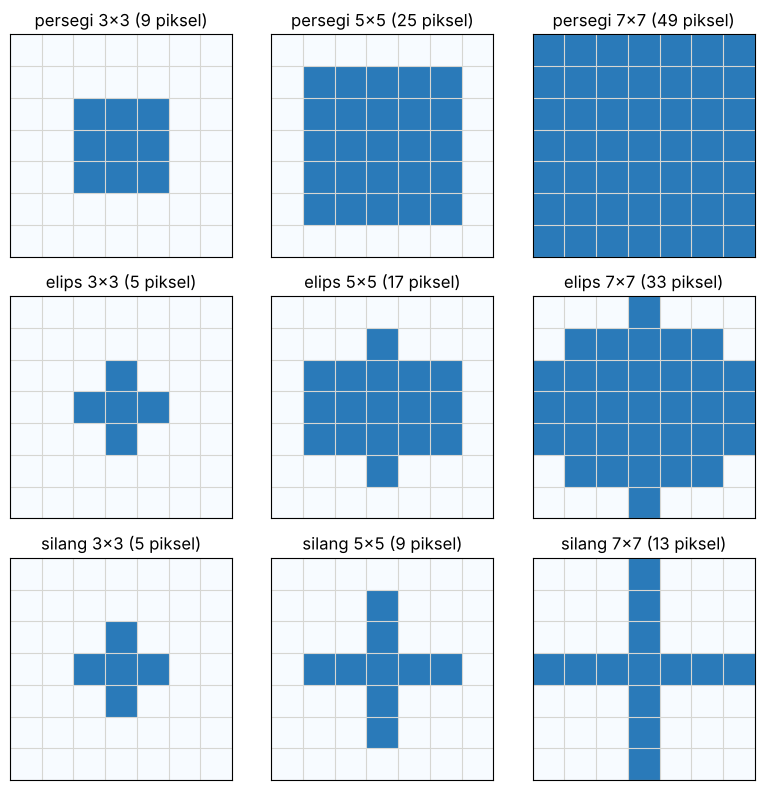

In [12]:
fig, ax = plt.subplots(3, 3, figsize=(8, 8))
for i, (nb, kb) in enumerate(bentuk.items()):
    for j, uk in enumerate([3, 5, 7]):
        se = cv2.getStructuringElement(kb, (uk, uk))
        kanvas = np.zeros((7, 7), np.uint8); o = (7 - uk) // 2
        kanvas[o:o + uk, o:o + uk] = se
        ax[i, j].imshow(kanvas, cmap="Blues", vmin=0, vmax=1.4)
        ax[i, j].set_xticks(np.arange(-.5, 7, 1), minor=True); ax[i, j].set_yticks(np.arange(-.5, 7, 1), minor=True)
        ax[i, j].grid(which="minor", color="#d6d6d2", lw=0.8); ax[i, j].tick_params(which="both", length=0, labelbottom=False, labelleft=False)
        ax[i, j].set_title(f"{nb} {uk}x{uk} ({int(se.sum())} piksel)")
plt.tight_layout(); simpan("p6_bentuk_se.png"); plt.show()

Elips 3 × 3 dari OpenCV sama persis dengan silang 3 × 3 (5 piksel), sehingga baris elips 3 dan silang 3 di Tabel 9 identik. Elips 5 dan 7 paling mendekati lingkaran. Opening dengan elips membuang benda yang lebih sempit dari SE ke **segala arah** secara merata, cocok untuk bercak bundar. Persegi lebih agresif di sudut, sedangkan silang lebih lemah pada arah diagonal: tulang daun miring lolos lebih banyak (galat jumlah sehat silang 5 = 7,15).

## Bagian 4. Komponen Terhubung dan Pengukuran Bercak
### Langkah 4.1 Lembar hitung manual (dicek dengan kode)
Keliling manual = jumlah sisi piksel yang berbatasan dengan latar. OpenCV (`cv2.arcLength`) mengukur panjang kontur yang melewati **pusat** piksel tepi. 1 piksel = 0,4375 mm.

In [13]:
MM_PER_PX = 0.4375            # dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px

def keliling_sisi(m_):
    p = np.pad(m_.astype(bool), 1)
    inti = p[1:-1, 1:-1]
    return int(sum((inti & ~np.roll(p, s, axis=a)[1:-1, 1:-1]).sum() for a in (0, 1) for s in (1, -1)))

objek = {"bercak 3x3": close_open_B, "garis 1x6": np.pad(B[7:8, :], ((7, 1), (0, 0)))}
for nm, m_ in objek.items():
    A = int(m_.sum()); P_m = keliling_sisi(m_)
    kontur, _ = cv2.findContours(m_.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    P_cv = cv2.arcLength(kontur[0], True); w, h = cv2.minAreaRect(kontur[0])[1]
    ys, xs = np.nonzero(m_); bw, bh = np.ptp(xs) + 1, np.ptp(ys) + 1
    print(f"{nm}: luas {A} px = {A * MM_PER_PX ** 2:.4f} mm2 | manual: keliling {P_m}, "
          f"kebulatan {4 * np.pi * A / P_m ** 2:.3f}, rasio {max(bw, bh) / min(bw, bh):.0f} | "
          f"OpenCV: keliling {P_cv:.0f}, kebulatan {4 * np.pi * A / P_cv ** 2:.3f}, rasio minAreaRect {max(w, h) / max(min(w, h), 1):.0f}")

bercak 3x3: luas 9 px = 1.7227 mm2 | manual: keliling 12, kebulatan 0.785, rasio 1 | OpenCV: keliling 8, kebulatan 1.767, rasio minAreaRect 1
garis 1x6: luas 6 px = 1.1484 mm2 | manual: keliling 14, kebulatan 0.385, rasio 6 | OpenCV: keliling 10, kebulatan 0.754, rasio minAreaRect 5


- Bercak 3 × 3: luas 9 px = 1,7227 mm², keliling 12, kebulatan 4π·9/144 = 0,785, rasio aspek 1.
- Garis 1 × 6: luas 6 px = 1,1484 mm², keliling 14, kebulatan 4π·6/196 = 0,385, rasio aspek 6.
- Aturan sederhana: bercak bila kebulatan ≥ 0,5 **dan** rasio aspek ≤ 2.
- OpenCV mengukur kontur lewat pusat piksel, sehingga keliling bercak 3 × 3 hanya 8. Kebulatannya jadi 1,767 (> 1), dan kebulatan garis naik ke 0,754. Pada komponen kecil, kebulatan OpenCV tidak dapat dipercaya. Karena itu syarat **luas minimum** diterapkan bersama syarat bentuk.

### Langkah 4.2 Label dan ukur
**Kode 4.1** Komponen terhubung dan pengukuran setiap bercak (teh_041, opening lalu closing elips 5 tanpa penyaringan)

konektivitas 4: 22 komponen
konektivitas 8: 22 komponen
    label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0       1      386     73.88         71.9       0.94         1.15  308  154
1       2      251     48.04         56.6       0.98         1.06  533  204
2       3      928    177.62        168.0       0.41         1.77  366  238
3       4       51      9.76         41.5       0.37         3.57  575  224
4       5      103     19.71         73.6       0.24         5.44  536  228
5       6      104     19.91         72.8       0.25         6.06  487  234
6       7       17      3.25         13.7       1.15         1.25  510  232
7       8      197     37.71         50.6       0.97         1.14  151  245
8       9       27      5.17         17.7       1.09         1.50  445  239
9      10       17      3.25         13.7       1.15         1.25  420  242
10     11       82     15.70         47.6       0.46         3.80  331  251
11     12       42      8.04    

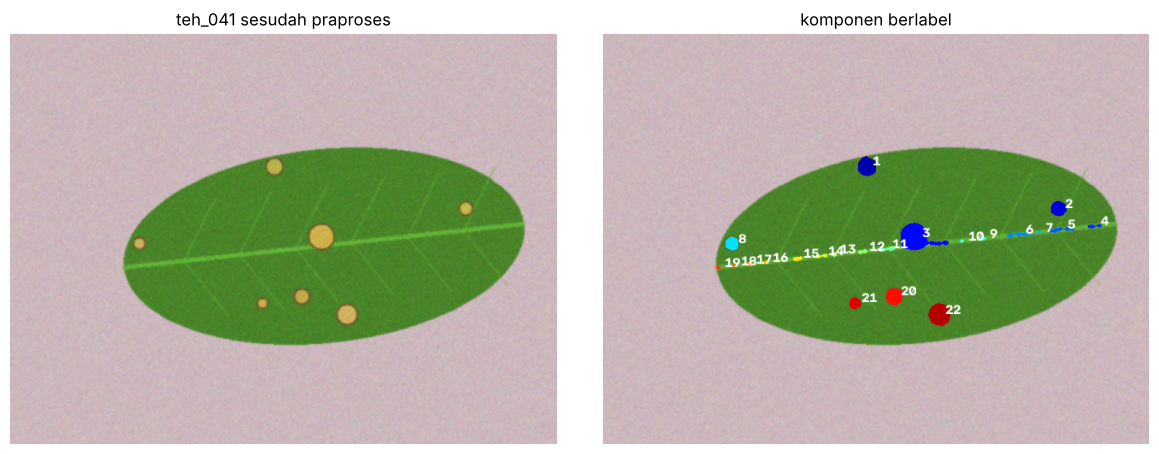

In [14]:
def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1), round(kebulatan, 2),
                      round(rasio, 2), int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl

img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                          cv2.MORPH_CLOSE, SE(5))
for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")
tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)
tabel_kom.to_csv("../hasil/p6_tabel10_teh041.csv", index=False)

warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))
simpan("p6_label_teh041.png"); plt.show()

**Temuan Tabel 10:** 22 komponen, sama untuk konektivitas 4 dan 8.
- Bercak asli: label 1, 2, 3, 8, 20, 21, dan 22 (7 bercak, 147–928 px = 28–178 mm²).
- Label 3 (928 px) adalah bercak terbesar yang menempel pada potongan tulang daun utama, sehingga kebulatannya hanya 0,41 dan rasionya 1,77.
- 15 komponen lain (17–104 px) adalah potongan tulang daun utama, terlihat dari letaknya yang sejajar di sepanjang tulang daun. Bentuknya kecil (17–45 px; yang 17 px berkebulatan OpenCV 1,15) atau memanjang (rasio sampai 6,1).

**Bukti P3.2: konektivitas 4 vs 8 pada seluruh dataset** (citra sesudah opening lalu closing elips 5).

In [15]:
beda = []
for _, d in label.iterrows():
    b = cv2.morphologyEx(cv2.morphologyEx(B0[d.nama_file], cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    n4, n8 = jumlah_komponen(b, 4), jumlah_komponen(b, 8)
    if n4 != n8:
        beda.append([d.nama_file, d.kelas, n4, n8])
print(f"citra dengan jumlah komponen berbeda antara konektivitas 4 dan 8: {len(beda)} dari 60")
print(pd.DataFrame(beda, columns=["citra", "kelas", "konek4", "konek8"]))

citra dengan jumlah komponen berbeda antara konektivitas 4 dan 8: 3 dari 60
         citra  kelas  konek4  konek8
0  teh_001.png  sehat      19      17
1  teh_017.png  sehat      18      16
2  teh_018.png  sehat      18      17


**Temuan P3.2:** hanya 3 dari 60 citra (semuanya daun sehat) yang jumlah komponennya berbeda antara konektivitas 4 dan 8, dan selisihnya berasal dari potongan tulang daun yang bersentuhan di sudut. Bercak asli padat, jadi keduanya memberi jumlah sama. Konektivitas 8 dipakai agar satu bercak bertepi bergerigi tidak terhitung dua.

### Langkah 4.3 Saring bercak palsu
**Kode 4.2** Penyaringan komponen berdasarkan ukuran dan bentuk

In [16]:
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >= bulat_min)
                    & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99), "luas + kebulatan + rasio": (20, 0.5, 1.8)}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])
uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
print(uji.pivot_table(index="aturan", columns="kelas", values="galat").round(2))
print("Daun sehat yang masih memiliki bercak palsu:")
print(uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0).groupby("aturan").palsu.sum())

kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           0.30    0.25   2.30
luas + kebulatan + rasio   0.15    0.25   0.95
luas >= 20                 0.60    0.40   3.35
tanpa saring               1.00    0.65   4.45
Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan            6
luas + kebulatan + rasio    5
luas >= 20                  7
tanpa saring                9
Name: palsu, dtype: int64


**Tabel 11** (urutan sesuai petunjuk), ditambah aturan final modul (luas ≥ 40, kebulatan ≥ 0,4, rasio ≤ 1,8) sebagai pembanding.

In [17]:
aturan_final = {"final: luas>=40, bulat>=0.4, rasio<=1.8": (40, 0.4, 1.8)}
baris = []
for _, d in label.iterrows():
    mb = muat(d.nama_file)[2]
    bersih = cv2.morphologyEx(cv2.morphologyEx(B0[d.nama_file], cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan_final.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])
uji2 = pd.concat([uji, pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"]).assign(
    galat=lambda t: (t.jumlah - t.acuan).abs())])
tabel11 = uji2.pivot_table(index="aturan", columns="kelas", values="galat")[["berat", "ringan", "sehat"]].add_prefix("galat_")
tabel11["daun_sehat_dgn_bercak_palsu"] = uji2[uji2.kelas == "sehat"].assign(p=lambda t: t.jumlah > 0).groupby("aturan").p.sum()
tabel11 = tabel11.loc[list(aturan) + list(aturan_final)].round(2)
tabel11.to_csv("../hasil/p6_tabel11.csv")
tabel11

kelas,galat_berat,galat_ringan,galat_sehat,daun_sehat_dgn_bercak_palsu
aturan,,,,
tanpa saring,1.00,0.65,4.45,9
luas >= 20,0.60,0.40,3.35,7
luas + kebulatan,0.30,0.25,2.30,6
luas + kebulatan + rasio,0.15,0.25,0.95,5
"final: luas>=40, bulat>=0.4, rasio<=1.8",0.00,0.20,0.00,0


**Temuan Tabel 11:**
- Setiap aturan menurunkan galat jumlah, tetapi aturan bawaan lengkap (luas ≥ 20 + kebulatan ≥ 0,5 + rasio ≤ 1,8) masih menyisakan bercak palsu pada 5 daun sehat (galat 0,95).
- Rasio aspek paling banyak memangkas galat sehat (2,30 → 0,95), karena potongan tulang daun memanjang.
- Aturan final (luas ≥ 40) menghilangkan semua bercak palsu di daun sehat. Galat berat dan sehat 0, galat ringan 0,20.

### Langkah 4.4 Kerjakan sendiri: dasar ambang penyaringan
Setiap komponen hasil pembersihan final (opening elips 5, closing elips 3) pada 60 citra diberi tanda **benar** bila > 50% pikselnya ada di mask bercak acuan, selain itu **palsu**.

benar                False    True 
luas_px     count   141.00   207.00
            mean     60.79   361.58
            std     139.79   218.60
            min      17.00    39.00
            5%       17.00    75.30
            25%      17.00   176.00
            50%      30.00   344.00
            75%      54.00   506.00
            max    1510.00  1072.00
kebulatan   count   141.00   207.00
            mean      0.85     0.92
            std       0.33     0.11
            min       0.03     0.33
            5%        0.24     0.77
            25%       0.55     0.90
            50%       1.03     0.94
            75%       1.15     0.97
            max       1.15     1.10
rasio_aspek count   141.00   207.00
            mean      2.91     1.07
            std       4.63     0.11
            min       1.00     1.00
            5%        1.25     1.00
            25%       1.25     1.00
            50%       1.67     1.04
            75%       2.89     1.08
            max      48.66  

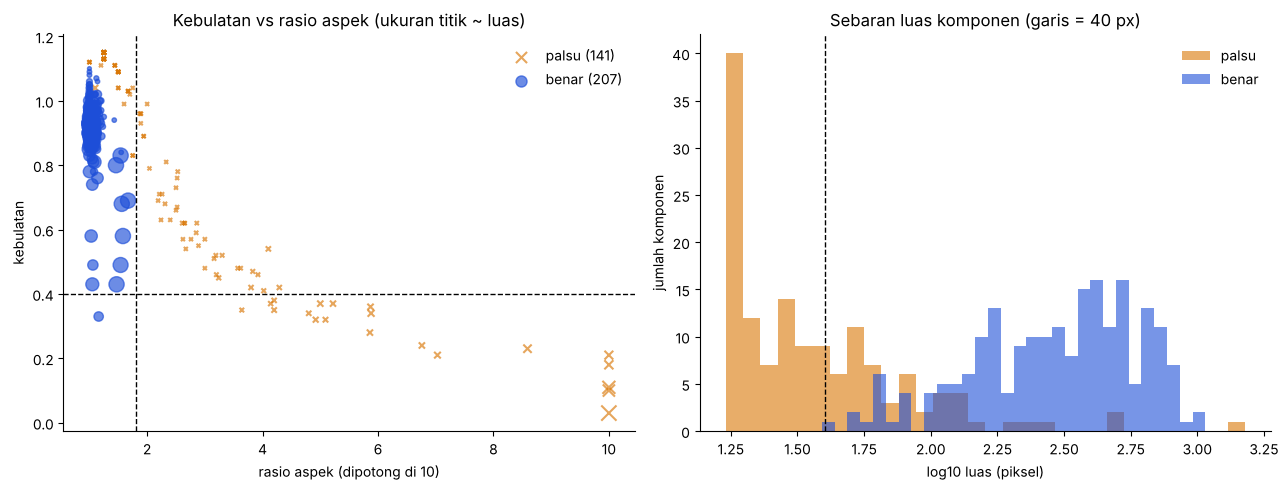

In [18]:
baris = []
for _, d in label.iterrows():
    mb = muat(d.nama_file)[2]
    b = cv2.morphologyEx(cv2.morphologyEx(B0[d.nama_file], cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(3))
    t, lbl = ukur_komponen(b)
    for _, r in t.iterrows():
        baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, r.luas_px, r.kebulatan, r.rasio_aspek,
                      bool((mb[lbl == r.label] > 0).mean() > 0.5)])
komp = pd.DataFrame(baris, columns=["citra", "kelas", "kondisi", "luas_px", "kebulatan", "rasio_aspek", "benar"])
komp.to_csv("../hasil/p6_komponen.csv", index=False)
print(komp.groupby("benar")[["luas_px", "kebulatan", "rasio_aspek"]].describe(percentiles=[.05, .25, .5, .75]).T.round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for benar, wr, mk, nm in [(False, "#d97706", "x", "palsu"), (True, "#1d4ed8", "o", "benar")]:
    t = komp[komp.benar == benar]
    ax[0].scatter(t.rasio_aspek.clip(upper=10), t.kebulatan, s=np.clip(t.luas_px / 6, 8, 120), c=wr, marker=mk,
                  alpha=0.65, label=f"{nm} ({len(t)})")
    ax[1].hist(np.log10(t.luas_px.clip(lower=1)), bins=30, alpha=0.6, color=wr, label=nm)
ax[0].axvline(1.8, color="k", ls="--", lw=1); ax[0].axhline(0.4, color="k", ls="--", lw=1)
ax[0].set_xlabel("rasio aspek (dipotong di 10)"); ax[0].set_ylabel("kebulatan"); ax[0].legend(frameon=False)
ax[0].set_title("Kebulatan vs rasio aspek (ukuran titik ~ luas)")
ax[1].axvline(np.log10(40), color="k", ls="--", lw=1)
ax[1].set_xlabel("log10 luas (piksel)"); ax[1].set_ylabel("jumlah komponen"); ax[1].legend(frameon=False)
ax[1].set_title("Sebaran luas komponen (garis = 40 px)")
for a in ax:
    for s in ["top", "right"]: a.spines[s].set_visible(False)
plt.tight_layout(); simpan("p6_sebar_komponen.png"); plt.show()

In [19]:
# Berapa komponen benar dan palsu yang lolos tiap aturan?
for nm, (a, b, r) in {"luas>=20, bulat>=0.5, rasio<=1.8 (bawaan)": (20, 0.5, 1.8),
                      "luas>=40, bulat>=0.4, rasio<=1.8 (final)": (40, 0.4, 1.8),
                      "luas>=40 saja": (40, 0, 99), "bulat>=0.4 & rasio<=1.8 saja": (0, 0.4, 1.8)}.items():
    lolos = (komp.luas_px >= a) & (komp.kebulatan >= b) & (komp.rasio_aspek <= r)
    print(f"{nm:42s} benar lolos {int((lolos & komp.benar).sum()):3d}/{int(komp.benar.sum())}, "
          f"luas benar lolos {komp[lolos & komp.benar].luas_px.sum() / komp[komp.benar].luas_px.sum():.3f}, "
          f"palsu lolos {int((lolos & ~komp.benar).sum()):3d}/{int((~komp.benar).sum())}")
print("\nKomponen benar yang terbuang aturan final:")
print(komp[komp.benar & ~((komp.luas_px >= 40) & (komp.kebulatan >= 0.4) & (komp.rasio_aspek <= 1.8))])
print("\nKomponen palsu yang lolos aturan final:")
print(komp[~komp.benar & (komp.luas_px >= 40) & (komp.kebulatan >= 0.4) & (komp.rasio_aspek <= 1.8)])

luas>=20, bulat>=0.5, rasio<=1.8 (bawaan)  benar lolos 202/207, luas benar lolos 0.966, palsu lolos  37/141
luas>=40, bulat>=0.4, rasio<=1.8 (final)   benar lolos 205/207, luas benar lolos 0.996, palsu lolos   1/141
luas>=40 saja                              benar lolos 206/207, luas benar lolos 0.999, palsu lolos  51/141
bulat>=0.4 & rasio<=1.8 saja               benar lolos 206/207, luas benar lolos 0.996, palsu lolos  77/141

Komponen benar yang terbuang aturan final:
           citra   kelas   kondisi  luas_px  kebulatan  rasio_aspek  benar
120  teh_030.png  ringan  bayangan     39.0       1.10         1.00   True
324  teh_058.png   berat    terang    276.0       0.33         1.16   True

Komponen palsu yang lolos aturan final:
           citra   kelas kondisi  luas_px  kebulatan  rasio_aspek  benar
129  teh_032.png  ringan   gelap    112.0       1.04          1.1  False


**Temuan Langkah 4.4:**
- Komponen palsu umumnya kecil (median 30 px, 75% ≤ 54 px). Bercak benar mulai 39 px (5% terkecil ≤ 75 px).
- Semua bercak benar berasio ≤ 1,67 dan 95% berkebulatan ≥ 0,77. Komponen palsu yang besar (tulang daun) berasio sampai 48,7.
- Aturan final meloloskan 205 dari 207 bercak benar (99,6% luasnya) dan hanya 1 dari 141 komponen palsu.
  - Dua bercak benar terbuang: teh_030 (39 px, sedikit di bawah luas 40) dan teh_058 (276 px, kebulatan 0,33 karena dua bercak menyatu tidak rapi).
  - Satu komponen "palsu" yang lolos, di teh_032, sebenarnya bercak asli yang tersegmentasi kebesaran (112 px vs acuan ≈ 58 px), sehingga kurang dari separuh pikselnya ada di mask acuan.
- Luas saja (≥ 40) masih meloloskan 51 komponen palsu; bentuk saja meloloskan 77. Keduanya diperlukan bersama.

**Bukti P4.4: luas total bercak teh_041**, untuk hasil Kode 4.1 (tanpa saring) dan hasil modul final. Nilai kanal R pada cincin cokelat (2 piksel terluar mask bercak), inti bercak, dan daun dibandingkan dengan ambang median + 4·MAD.

In [20]:
img, md, mb = muat("teh_041.png"); pra_ = PRA["teh_041.png"]; m_daun = mask_daun_awal(pra_)
R_ = pra_[:, :, 2].astype(float); daun = m_daun > 0
med = np.median(R_[daun]); mad = 1.4826 * np.median(np.abs(R_[daun] - med)); T = med + 4 * mad
cincin = (mb > 0) & ~(cv2.erode(mb, SE(5)) > 0)
inti = cv2.erode(mb, SE(5)) > 0
print(f"ambang R = median {med:.1f} + 4 x MAD {mad:.2f} = {T:.1f}")
print(f"rerata R: daun sehat {R_[daun & (mb == 0)].mean():.1f}, cincin cokelat {R_[cincin].mean():.1f} "
      f"(lolos ambang {100 * (R_[cincin] > T).mean():.1f}%), inti bercak {R_[inti].mean():.1f}")
b0_ = bercak_awal(pra_, m_daun)
kode41 = cv2.morphologyEx(cv2.morphologyEx(b0_, cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
langkah = {"bercak awal": b0_, "opening 5": cv2.morphologyEx(b0_, cv2.MORPH_OPEN, SE(5)),
           "Kode 4.1 (open 5 + close 5)": kode41,
           "final (open 5 + close 3 + saring)": ukur_saring(cv2.morphologyEx(cv2.morphologyEx(b0_, cv2.MORPH_OPEN, SE(5)),
                                                                             cv2.MORPH_CLOSE, SE(3)), 40, 0.4, 1.8)}
A_acuan = int((mb > 0).sum())
for nm, m_ in langkah.items():
    A = int((m_ > 0).sum()); irisan = int(((m_ > 0) & (mb > 0)).sum())
    print(f"{nm:34s} luas {A:5d} px ({A * MM_PER_PX ** 2:6.1f} mm2) vs acuan {A_acuan} px: selisih {100 * (A - A_acuan) / A_acuan:+6.1f}% "
          f"| irisan {irisan} | lebih {A - irisan} | kurang {A_acuan - irisan}")

ambang R = median 74.0 + 4 x MAD 4.45 = 91.8
rerata R: daun sehat 75.0, cincin cokelat 117.0 (lolos ambang 95.1%), inti bercak 196.2
bercak awal                        luas  5224 px ( 999.9 mm2) vs acuan 2619 px: selisih  +99.5% | irisan 2576 | lebih 2648 | kurang 43
opening 5                          luas  3354 px ( 642.0 mm2) vs acuan 2619 px: selisih  +28.1% | irisan 2565 | lebih 789 | kurang 54
Kode 4.1 (open 5 + close 5)        luas  3388 px ( 648.5 mm2) vs acuan 2619 px: selisih  +29.4% | irisan 2566 | lebih 822 | kurang 53
final (open 5 + close 3 + saring)  luas  2645 px ( 506.3 mm2) vs acuan 2619 px: selisih   +1.0% | irisan 2565 | lebih 80 | kurang 54


**Temuan P4.4:**
- Hasil akhir teh_041: 2.645 px (506,3 mm²) vs acuan 2.619 px, **lebih besar 1,0%**. Ada 80 px berlebih dan 54 px kurang.
- Cincin cokelat (R ≈ 117) jauh di atas ambang 91,8, sehingga 95% pikselnya ikut sebagai bercak. Ini benar, karena mask acuan juga mencakup cincin (jari-jari r + 2).
- Kelebihan 80 px datang dari median 3 × 3 pada praproses, yang melebarkan tepi terang sekitar 1 px, dan dari closing yang mengisi lekukan di batas bercak.
- Kekurangan 54 px adalah piksel cincin paling luar yang tercampur warna daun.
- Tanpa penyaringan (Kode 4.1), luasnya +29,4% karena potongan tulang daun ikut terhitung.

## Bagian 5. Integrasi: Modul `src/bercak.py`
### Langkah 5.1 Modul
Ketujuh TODO dilengkapi di `src/bercak.py`:
- **TODO 1–2:** opening lalu closing.
- **TODO 3:** `connectedComponentsWithStats`, konektivitas 8.
- **TODO 4:** luas, `arcLength`, kebulatan, dan rasio dari `minAreaRect`.
- **TODO 5:** komponen hanya masuk mask bila lolos ketiga syarat.
- **TODO 6:** persen = luas bercak / luas mask daun × 100.
- **TODO 7:** kelas dari `batas_ringan` dan `batas_berat`.

In [21]:
import inspect, importlib, bercak
importlib.reload(bercak)
print(inspect.getsource(bercak.bersihkan)); print(inspect.getsource(bercak.ukur_dan_saring))

def bersihkan(biner, p):
    """Opening membuang titik derau dan potongan tipis; closing menutup celah."""
    # TODO 1: opening (erosi lalu dilasi) membuang objek yang lebih sempit dari SE
    if p["se_open"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_OPEN, _se(p, p["se_open"]))
    # TODO 2: closing (dilasi lalu erosi) menutup lubang dan celah kecil di dalam bercak
    if p["se_close"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_CLOSE, _se(p, p["se_close"]))
    return biner

def ukur_dan_saring(biner, p):
    """Mengembalikan mask bercak tersaring dan daftar ukuran setiap bercak."""
    # TODO 3: label komponen terhubung, konektivitas 8 (bercak nyata tidak
    #         terputus hanya karena dua pikselnya bersentuhan di sudut)
    n, lbl, st, cen = cv2.connectedComponentsWithStats((biner > 0).astype(np.uint8),
                                                       connectivity=8)
    keluar, daftar = np.zeros_like(biner), []
    for i in range(1, n):
        k

### Langkah 5.2 Evaluasi menyeluruh
**Kode 5.2** Evaluasi modul `bercak.py` dengan parameter final:
- **k = 4, SE elips, opening 5:** Tabel 9.
- **Closing 3:** tabel ukuran closing.
- **Luas ≥ 40, kebulatan ≥ 0,4, rasio ≤ 1,8:** Langkah 4.4.
- **Batas kelas:** tetap bawaan (0,1% dan 2,0%).

Galat absolut rerata persen bercak: 0.229
Korelasi persen prediksi vs acuan : 0.981
Akurasi kelas                     : 0.983
prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             20              0      0
Bercak Ringan             0             19      1
Sehat                     0              0     20
kondisi
bayangan          0.92
gelap             1.00
kontras_rendah    1.00
normal            1.00
terang            1.00
Name: benar, dtype: float64


Text(0, 0.5, 'persen bercak prediksi')

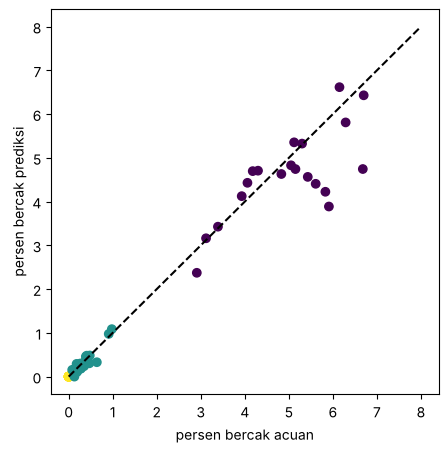

In [22]:
import importlib, bercak
importlib.reload(bercak)
PB = {"se_close": 3, "luas_min": 40, "bulat_min": 0.4}     # parameter lain = bawaan
bercak.simpan_param(PB)

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"],
                  jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan", "persen_prediksi",
                                  "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)

print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas                     :", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))
print(ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))

plt.figure(figsize=(5, 5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes)
plt.plot([0, 8], [0, 8], "k--"); plt.xlabel("persen bercak acuan"); plt.ylabel("persen bercak prediksi")

**Tabel 12**, dibandingkan dengan parameter bawaan (`PB = {}`)

In [23]:
def ringkas_ev(e):
    salah = e[e.kelas_prediksi != e.kelas_acuan]
    akurasi_k = e.assign(b=e.kelas_prediksi == e.kelas_acuan).groupby("kondisi").b.mean()
    return {"Galat absolut rerata persen bercak": round((e.persen_prediksi - e.persen_acuan).abs().mean(), 3),
            "Korelasi persen prediksi dan acuan": round(e[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1], 3),
            "Akurasi kelas": round((e.kelas_prediksi == e.kelas_acuan).mean(), 3),
            "Galat jumlah bercak rerata": round((e.jumlah_prediksi - e.jumlah_acuan).abs().mean(), 3),
            "Jumlah daun sehat yang dinilai berbercak": int(((e.kelas == "sehat") & (e.kelas_prediksi != "Sehat")).sum()),
            "Jumlah daun berbercak yang dinilai sehat": int(((e.kelas != "sehat") & (e.kelas_prediksi == "Sehat")).sum()),
            "Kondisi cahaya dengan akurasi terendah": f"{akurasi_k.idxmin()} ({akurasi_k.min():.2f})",
            "Citra salah kelas": ", ".join(salah.nama.str[:7])}
ev_bawaan = []
for _, d in label.iterrows():
    mb = muat(d.nama_file)[2]
    h = bercak.analisis_daun(PRA[d.nama_file], {})
    ev_bawaan.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"],
                      jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]])
ev_bawaan = pd.DataFrame(ev_bawaan, columns=ev.columns[:-1]).assign(kelas_acuan=ev.kelas_acuan)
tabel12 = pd.DataFrame({"final": ringkas_ev(ev), "bawaan (PB = {})": ringkas_ev(ev_bawaan)})
tabel12.to_csv("../hasil/p6_tabel12.csv")
tabel12

,final,bawaan (PB = {})
Galat absolut rerata persen bercak,0.229,0.268
Korelasi persen prediksi dan acuan,0.981,0.979
Akurasi kelas,0.983,0.917
Galat jumlah bercak rerata,0.05,0.45
Jumlah daun sehat yang dinilai berbercak,0,4
Jumlah daun berbercak yang dinilai sehat,1,1
Kondisi cahaya dengan akurasi terendah,bayangan (0.92),terang (0.83)
Citra salah kelas,teh_030,"teh_001, teh_013, teh_017, teh_018, teh_030"


**Temuan Tabel 12:**
- Parameter final menaikkan akurasi dari 0,917 ke 0,983 (59 dari 60) dan menghilangkan semua daun sehat yang dinilai berbercak (4 → 0).
- Galat jumlah bercak turun 0,45 → 0,05, dan MAE persen turun 0,268 → 0,229.
- Satu-satunya kesalahan adalah teh_030 (ringan, bayangan), yang dinilai Sehat.

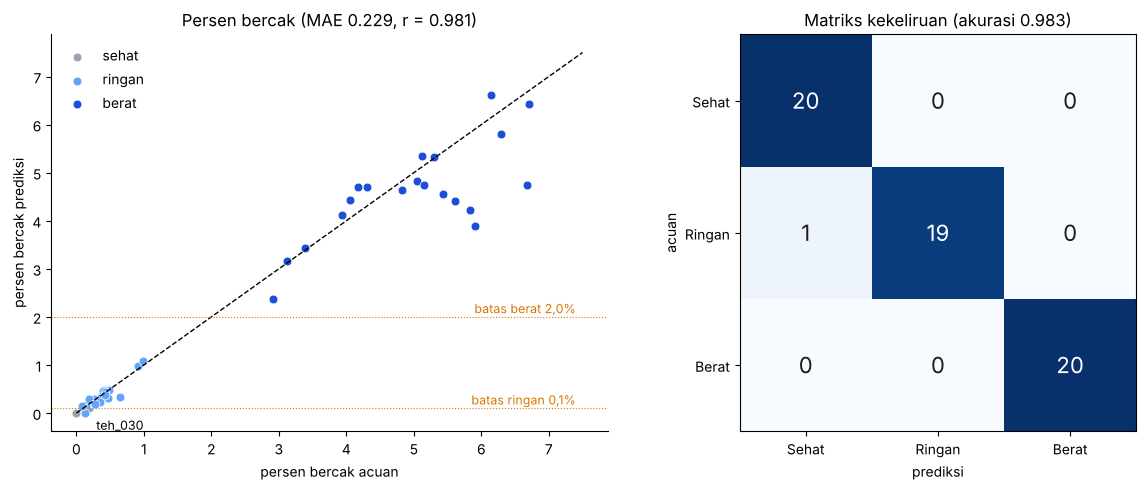

                 mean  <lambda_0>
kondisi                          
normal          0.058       0.106
gelap           0.007       0.090
terang          0.065       0.145
kontras_rendah -0.315       0.322
bayangan       -0.482       0.482


In [24]:
# Diagram sebar dan matriks kekeliruan untuk laporan dan slide
WARNA = {"sehat": "#9ca3af", "ringan": "#60a5fa", "berat": "#1d4ed8"}
fig, ax = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1.15, 1]})
for kl, w in WARNA.items():
    t = ev[ev.kelas == kl]
    ax[0].scatter(t.persen_acuan, t.persen_prediksi, c=w, s=40, label=kl, edgecolor="white", lw=0.5)
ax[0].plot([0, 7.5], [0, 7.5], "k--", lw=1)
for y, nm in [(0.1, "batas ringan 0,1%"), (2.0, "batas berat 2,0%")]:
    ax[0].axhline(y, color="#d97706", lw=0.8, ls=":"); ax[0].text(7.4, y + 0.08, nm, ha="right", fontsize=9, color="#d97706")
salah = ev[ev.kelas_prediksi != ev.kelas_acuan]
for _, r in salah.iterrows():
    ax[0].annotate(r.nama[:7], (r.persen_acuan, r.persen_prediksi), xytext=(8, -12), textcoords="offset points", fontsize=9)
ax[0].set_xlabel("persen bercak acuan"); ax[0].set_ylabel("persen bercak prediksi"); ax[0].legend(frameon=False)
ax[0].set_title(f"Persen bercak (MAE {tabel12.loc['Galat absolut rerata persen bercak', 'final']}, r = {tabel12.loc['Korelasi persen prediksi dan acuan', 'final']})")
urut = ["Sehat", "Bercak Ringan", "Bercak Berat"]
cm = pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi).reindex(index=urut, columns=urut, fill_value=0)
ax[1].imshow(cm.values, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax[1].text(j, i, cm.values[i, j], ha="center", va="center", fontsize=16,
                   color="white" if cm.values[i, j] > 10 else "#1d1d1b")
ax[1].set_xticks(range(3), ["Sehat", "Ringan", "Berat"]); ax[1].set_yticks(range(3), ["Sehat", "Ringan", "Berat"])
ax[1].set_xlabel("prediksi"); ax[1].set_ylabel("acuan"); ax[1].set_title(f"Matriks kekeliruan (akurasi {tabel12.loc['Akurasi kelas', 'final']})")
for s in ["top", "right"]: ax[0].spines[s].set_visible(False)
plt.tight_layout(); simpan("p6_evaluasi_bercak.png"); plt.show()
print(ev.assign(galat=ev.persen_prediksi - ev.persen_acuan).groupby("kondisi").galat.agg(["mean", lambda s: s.abs().mean()]).round(3).loc[URUT])

### Langkah 5.3 Kerjakan sendiri: analisis kesalahan
Hanya satu citra yang salah kelas. Dua citra dengan galat persen terbesar ikut ditampilkan karena penyebabnya sama.

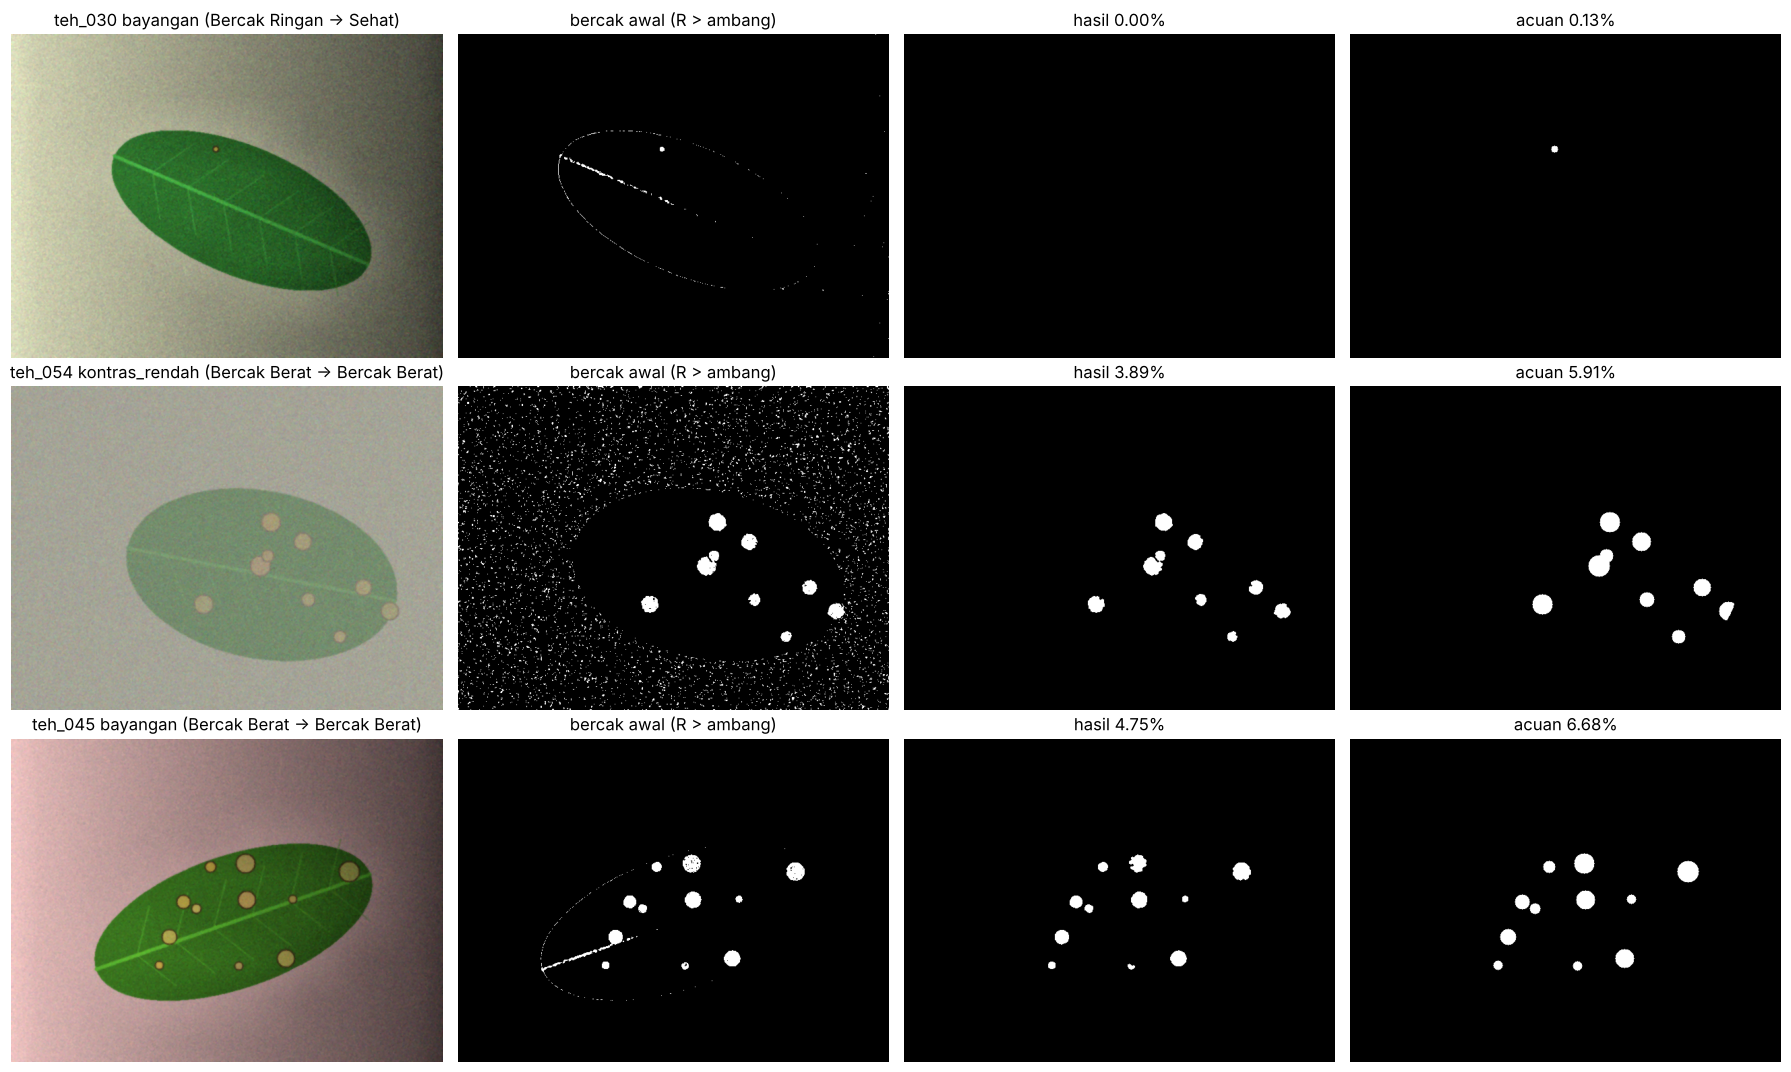

                                             0               1             2
citra                              teh_030.png     teh_054.png   teh_045.png
kondisi                               bayangan  kontras_rendah      bayangan
acuan                            Bercak Ringan    Bercak Berat  Bercak Berat
prediksi                                 Sehat    Bercak Berat  Bercak Berat
persen_acuan                              0.13            5.91          6.68
persen_pred                                0.0           3.888         4.745
median_R                                  40.0           119.0          50.0
MAD_R                                     7.41            7.41           8.9
ambang_R                                  69.7           148.7          85.6
R_bercak_acuan                            87.8           154.6         118.5
persen_piksel_bercak_lolos                51.9            71.0          74.9
R_daun_sehat                              40.3           124.3          49.2

In [25]:
ev["galat"] = ev.persen_prediksi - ev.persen_acuan
ok = ev[ev.kelas_prediksi == ev.kelas_acuan]
tampilkan = list(ev[ev.kelas_prediksi != ev.kelas_acuan].nama) + list(ok.loc[ok.galat.abs().sort_values(ascending=False).index[:2]].nama)
panel, judul, diag = [], [], []
for nama in tampilkan:
    img, md, mb = muat(nama); pra_ = PRA[nama]
    h = bercak.analisis_daun(pra_, PB); r = ev[ev.nama == nama].iloc[0]
    R_ = pra_[:, :, 2].astype(float); daun = h["mask_daun"] > 0
    med = np.median(R_[daun]); mad = 1.4826 * np.median(np.abs(R_[daun] - med)); T = med + 4 * mad
    w4 = R_.shape[1] // 4
    diag.append([nama, r.kondisi, r.kelas_acuan, r.kelas_prediksi, r.persen_acuan, r.persen_prediksi, round(med, 1), round(mad, 2), round(T, 1),
                 round(R_[mb > 0].mean(), 1), round(100 * (R_[mb > 0] > T).mean(), 1),
                 round(R_[daun & (mb == 0)][:].mean(), 1),
                 round(R_[:, :w4][daun[:, :w4]].mean(), 1), round(R_[:, -w4:][daun[:, -w4:]].mean(), 1),
                 round(daun.sum() / (md > 0).sum(), 3), round(100 * ((mb > 0) & ~daun).sum() / (mb > 0).sum(), 1),
                 round(100 * (h["mask_bercak"] > 0).sum() / (md > 0).sum(), 3)])
    b0_ = bercak_awal(pra_, h["mask_daun"])
    panel += [pra_, b0_, h["mask_bercak"], mb]
    judul += [f"{nama[:7]} {r.kondisi} ({r.kelas_acuan} -> {r.kelas_prediksi})", "bercak awal (R > ambang)",
              f"hasil {r.persen_prediksi:.2f}%", f"acuan {r.persen_acuan:.2f}%"]
tampil(panel, judul, baris=len(tampilkan), ukuran=(18, 3.6 * len(tampilkan)))
simpan("p6_analisis_kesalahan.png"); plt.show()
print(pd.DataFrame(diag, columns=["citra", "kondisi", "acuan", "prediksi", "persen_acuan", "persen_pred", "median_R", "MAD_R", "ambang_R",
                                  "R_bercak_acuan", "persen_piksel_bercak_lolos", "R_daun_sehat", "R_daun_kiri", "R_daun_kanan",
                                  "luas_daun_hasil/acuan", "persen_bercak_di_luar_mask_daun", "persen_pred_dgn_luas_daun_acuan"]).T)

teh_030.png: pusat bercak x = 303 dari lebar 640 (sisi teduh di kanan), ambang global R = 69.7
R di bercak (acuan) = 87.8, R daun di sekitar bercak = 40.2, selisih lokal = 47.6


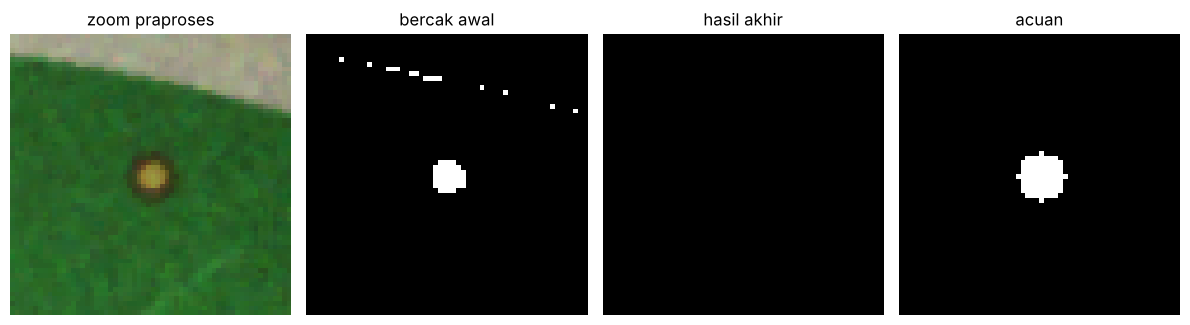

In [26]:
# Zoom pada bercak teh_030 (satu-satunya salah kelas)
nama = ev[ev.kelas_prediksi != ev.kelas_acuan].nama.iloc[0]
img, md, mb = muat(nama); pra_ = PRA[nama]; h = bercak.analisis_daun(pra_, PB)
ys, xs = np.nonzero(mb); cy, cx = int(ys.mean()), int(xs.mean()); r = 30
sl = (slice(max(cy - r, 0), cy + r), slice(max(cx - r, 0), cx + r))
R_ = pra_[:, :, 2].astype(float); daun = h["mask_daun"] > 0
med = np.median(R_[daun]); mad = 1.4826 * np.median(np.abs(R_[daun] - med)); T = med + 4 * mad
print(f"{nama}: pusat bercak x = {cx} dari lebar {R_.shape[1]} (sisi teduh di kanan), ambang global R = {T:.1f}")
print(f"R di bercak (acuan) = {R_[mb > 0].mean():.1f}, R daun di sekitar bercak = {R_[sl][(mb[sl] == 0) & daun[sl]].mean():.1f}, "
      f"selisih lokal = {R_[mb > 0].mean() - R_[sl][(mb[sl] == 0) & daun[sl]].mean():.1f}")
tampil([pra_[sl], bercak_awal(pra_, h["mask_daun"])[sl], h["mask_bercak"][sl], mb[sl]],
       ["zoom praproses", "bercak awal", "hasil akhir", "acuan"], ukuran=(12, 3.2))
simpan("p6_zoom_teh030.png"); plt.show()

**Penyebab kesalahan (Langkah 5.3):**
- **teh_030 (ringan → Sehat).** Satu bercak kecil (acuan 0,13%) di daun yang separuhnya teduh.
  - Ambang dihitung **global** dari median dan MAD seluruh daun. Gradien cahaya kiri–kanan (R daun kiri ≈ 54, kanan ≈ 31) ikut terhitung sebagai sebaran, sehingga MAD membengkak menjadi 7,41 (teh_041 normal: 4,45) dan ambang naik ke 69,7.
  - Panel zoom menunjukkan hanya inti bercak yang terang yang lolos (±52% piksel). Cincin cokelat jatuh di bawah ambang.
  - Inti yang tersisa sesudah opening tinggal 39 px, lalu terbuang oleh syarat luas ≥ 40.
  - Sumber kesalahan: **citra biner awal** (ambang global pada cahaya tidak rata), diperparah oleh penyaringan luas.
- **teh_045 dan teh_060 (bayangan, persen 27–29% lebih kecil).** Penyebabnya sama: cincin bercak di sisi teduh tidak lolos ambang (MAD teh_045 8,90), sehingga bercak di kanan tampak menyusut.
- **teh_054 (kontras rendah, 5,91% → 3,89%).** Otsu kanal S salah di dua arah: bintik-bintik nampan ikut masuk mask daun (luas daun 6,3% lebih besar), sedangkan 9,5% piksel bercak justru jatuh di luar mask. Hanya 71% piksel bercak lolos ambang 148,7. Dengan luas daun acuan, persennya hanya naik 3,89 → 4,13; sisa selisihnya berasal dari bercak yang terpotong mask dan cincin yang tidak lolos.
- Kesalahan kelas tidak berasal dari praproses (kondisi lain tidak salah). Yang perlu diganti di P7 adalah ambang global dan Otsu S.

**Bukti P5.2 dan P5.4: kepekaan terhadap batas kelas.** Sebaran persen acuan per kelas, lalu akurasi dan dua jenis kesalahan bila `batas_ringan` digeser. Persen prediksi tidak berubah; yang berubah hanya keputusan kelasnya.

In [27]:
print(label.groupby("kelas").persen_bercak.describe()[["min", "max"]].loc[["sehat", "ringan", "berat"]])
baris = []
for br in [0.02, 0.05, 0.1, 0.2, 0.3]:
    for bb in [1.0, 2.0, 2.5]:
        kp = np.where(ev.persen_prediksi >= bb, "Bercak Berat", np.where(ev.persen_prediksi >= br, "Bercak Ringan", "Sehat"))
        baris.append([br, bb, (kp == ev.kelas_acuan).mean(), int(((ev.kelas == "sehat") & (kp != "Sehat")).sum()),
                      int(((ev.kelas != "sehat") & (kp == "Sehat")).sum()),
                      int(((ev.kelas == "ringan") & (kp == "Bercak Berat")).sum()),
                      int(((ev.kelas == "berat") & (kp != "Bercak Berat")).sum())])
sens = pd.DataFrame(baris, columns=["batas_ringan", "batas_berat", "akurasi", "sehat->berbercak", "berbercak->sehat",
                                    "ringan->berat", "berat->bawah"]).round(3)
sens.to_csv("../hasil/p6_sensitivitas_batas.csv", index=False)
print(sens[sens.batas_berat == 2.0])
print("\nPersen prediksi terbesar pada daun sehat:", ev[ev.kelas == "sehat"].persen_prediksi.max(),
      "| terkecil pada daun berbercak:", ev[ev.kelas != "sehat"].persen_prediksi.min())

         min   max
kelas             
sehat   0.00  0.00
ringan  0.08  0.98
berat   2.91  6.70
    batas_ringan  batas_berat  akurasi  sehat->berbercak  berbercak->sehat  ringan->berat  berat->bawah
1           0.02          2.0    0.983                 0                 1              0             0
4           0.05          2.0    0.983                 0                 1              0             0
7           0.10          2.0    0.983                 0                 1              0             0
10          0.20          2.0    0.883                 0                 7              0             0
13          0.30          2.0    0.833                 0                10              0             0

Persen prediksi terbesar pada daun sehat: 0.0 | terkecil pada daun berbercak: 0.0


**Temuan:**
- Semua daun sehat bernilai persen 0, dan teh_030 juga 0. Karena itu batas ringan 0,02–0,10 memberi hasil sama, dan tidak ada batas yang dapat memperbaiki teh_030.
- Batas 0,2 sudah membuat 7 daun ringan dinilai sehat.
- Batas berat 2,0 aman karena ada celah lebar antara ringan terbesar (0,98) dan berat terkecil (2,91).

**Bukti Tabel 13: kepekaan parameter.** Satu parameter digeser dari nilai final, parameter lain tetap. Gunanya menunjukkan bahwa nilai final berada di wilayah yang stabil, bukan titik kebetulan. Semua angka dihitung pada 60 citra yang sama, jadi tetap optimistis (lihat P5.2).

In [28]:
geser = {"k": [3.0, 4.0, 5.0, 6.0], "se_open": [3, 5, 7], "se_close": [0, 3, 5, 7], "luas_min": [20, 30, 40, 60, 80],
         "bulat_min": [0.0, 0.3, 0.4, 0.5, 0.6], "rasio_maks": [1.5, 1.8, 2.5, 99]}
baris = []
for prm, nilai in geser.items():
    for v in nilai:
        P = {**PB, prm: v}; e = []
        for _, d in label.iterrows():
            h = bercak.analisis_daun(PRA[d.nama_file], P)
            e.append([d.kelas, d.persen_bercak, h["persen_bercak"], h["kelas"]])
        e = pd.DataFrame(e, columns=["kelas", "pa", "pp", "kp"])
        ka = e.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
        baris.append([prm, v, (e.pp - e.pa).abs().mean(), (e.kp == ka).mean(),
                      int(((e.kelas == "sehat") & (e.kp != "Sehat")).sum()), int(((e.kelas != "sehat") & (e.kp == "Sehat")).sum())])
kpk = pd.DataFrame(baris, columns=["parameter", "nilai", "MAE_persen", "akurasi", "sehat->berbercak", "berbercak->sehat"]).round(3)
kpk.to_csv("../hasil/p6_kepekaan_parameter.csv", index=False)
kpk

,parameter,nilai,MAE_persen,akurasi,sehat->berbercak,berbercak->sehat
0,k,3.0,0.253,0.983,0,1
1,k,4.0,0.229,0.983,0,1
2,k,5.0,0.271,0.967,0,2
3,k,6.0,0.357,0.933,0,4
4,se_open,3.0,0.254,0.983,0,1
5,se_open,5.0,0.229,0.983,0,1
6,se_open,7.0,0.246,0.967,0,2
7,se_close,0.0,0.246,0.983,0,1
8,se_close,3.0,0.229,0.983,0,1
9,se_close,5.0,0.246,0.983,0,1


**Temuan kepekaan:**
- Nilai final berada di dataran yang stabil: k 3–4, opening 3–5, closing 0–7, luas 40–60, kebulatan 0–0,4, dan rasio 1,8 semuanya memberi akurasi 0,983.
- Di luar dataran itu hasil memburuk. Luas 20 → 4 daun sehat berbercak palsu; rasio tanpa batas → 5; k 6 → 4 daun berbercak dinilai sehat; kebulatan 0,6 → MAE 0,287.

### Langkah 5.4 Tabel 13. Justifikasi parameter `bercak.py`

| Parameter | Nilai final | Alasan dan bukti | Risiko bila salah atur |
|---|---|---|---|
| kanal, k | R (2), 4,0 | Kanal R: KB tertinggi (P1–P4) dan tidak ada tepi tulang daun pada daun sehat (P5 Kode 2.3). k = 4: k = 3 memberi banyak bercak palsu sebelum penyaringan (galat jumlah sehat SE 3 = 33,4); k = 6 memotong bercak (IoU elips 5 turun 0,84 → 0,79). Kepekaan modul: k = 3 → MAE 0,253; k = 5–6 → 2–4 daun berbercak dinilai sehat | k terlalu kecil: tulang daun dan derau ikut; terlalu besar: bercak pucat atau di bayangan hilang |
| se_bentuk, se_open, se_close | elips, 5, 3 | Elips isotropik cocok untuk bercak bundar (panel SE). Opening 5 membuang struktur < 5 px (tulang daun 1–3 px), sedangkan bercak terkecil berdiameter ≈ 10 px. SE 3 masih menyisakan tulang daun (Tabel 9). Closing 3: bercak hilang paling sedikit (3 vs 4–6) dan tanpa penggabungan, sedangkan closing besar menyambung bercak ke potongan lain (lembar hitung 3.1c). Kepekaan: opening 7 → 2 daun berbercak dinilai sehat | Opening besar mengikis bercak ringan; closing besar menggabungkan bercak, sehingga jumlah salah dan bentuk memanjang lalu terbuang |
| luas_min | 40 px (≈ 7,7 mm², setara lingkaran Ø 3,1 mm) | Median luas komponen palsu 30 px, sedangkan bercak benar mulai 39 px (5% terkecil ≤ 75 px). Luas ≥ 20 masih menyisakan bercak palsu pada 5 daun sehat (Tabel 11); 40 → 0. Kepekaan: 40–60 stabil, 80 → 3 daun berbercak dinilai sehat. Masih di bawah target bercak terkecil 5 mm (≈ 11 px diameter) dari P2 | Terlalu besar: bercak awal (< 3 mm) tidak terhitung; terlalu kecil: titik derau jadi bercak |
| bulat_min, rasio_maks | 0,4; 1,8 | Diagram sebar: semua bercak benar berasio ≤ 1,67 dan 95% berkebulatan ≥ 0,77, sedangkan potongan tulang daun memanjang (rasio sampai 48,7). Aturan final meloloskan 205/207 bercak benar dan 1/141 komponen palsu. Kebulatan 0,5–0,6 membuang bercak yang menempel pada potongan lain (misalnya label 3 teh_041, kebulatan 0,41), sehingga MAE naik ke 0,259–0,287. Rasio 2,5 → 1 daun sehat berbercak palsu; tanpa batas → 5 | Bercak nyata yang tidak bundar atau dua bercak menyatu bisa terbuang (P5.5) |
| batas_ringan, batas_berat | 0,1%; 2,0% | Label: sehat 0%, ringan 0,08–0,98%, berat 2,91–6,70%. Batas berat 2,0 ada di celah lebar (0,98–2,91). Batas ringan 0,1 justru di atas ringan terkecil (0,08; teh_032 benar hanya karena hasilnya kebesaran). Pada data ini 0,02–0,10 memberi hasil sama, sedangkan 0,2 → 7 daun ringan dinilai sehat | Ditentukan dari seluruh label (bocor ke data uji), jadi akurasi terlalu optimistis; harus ditetapkan pada data latih/validasi (P11) dan dicek ke standar mutu |

## Tantangan opsional
### (a) Top-hat morfologi
Top-hat putih = citra − opening(citra) dengan SE lebih besar dari bercak terbesar (elips 41; bercak terbesar Ø ≈ 33 px). Hasilnya hanya menyisakan benda terang yang lebih kecil dari SE, sementara perubahan terang yang landai (bayangan) ikut terbuang. Ambang yang sama (median + 4·MAD) lalu diterapkan pada top-hat.

In [29]:
def bercak_tophat(img_bgr, mask_daun, kanal=2, k=4.0, uk=41):
    th = cv2.morphologyEx(img_bgr[:, :, kanal], cv2.MORPH_TOPHAT, SE(uk)).astype(np.float32)
    m_ = mask_daun > 0
    med = np.median(th[m_]); mad = 1.4826 * np.median(np.abs(th[m_] - med))
    return (((th > med + k * mad) & m_) * 255).astype(np.uint8)

P_final = {**bercak.PARAM_BERCAK, **PB}
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    mb = muat(d.nama_file)[2]; pra_ = PRA[d.nama_file]; m_daun = mask_daun_awal(pra_)
    b0_, t0 = bercak_awal(pra_, m_daun), bercak_tophat(pra_, m_daun)
    f0 = bercak.ukur_dan_saring(bercak.bersihkan(b0_, P_final), P_final)[0]
    f1 = bercak.ukur_dan_saring(bercak.bersihkan(t0, P_final), P_final)[0]
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, iou(b0_, mb), iou(t0, mb), iou(f0, mb), iou(f1, mb),
                  100 * (f1 > 0).sum() / (m_daun > 0).sum()])
th_ = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "IoU_awal", "IoU_tophat", "IoU_final_awal", "IoU_final_tophat", "persen_tophat"])
th_.to_csv("../hasil/p6_tophat.csv", index=False)
print(th_.groupby("kondisi")[["IoU_awal", "IoU_tophat", "IoU_final_awal", "IoU_final_tophat"]].mean().round(3).loc[URUT])
print(th_.groupby("kelas")[["IoU_awal", "IoU_tophat", "IoU_final_awal", "IoU_final_tophat"]].mean().round(3))
print(th_[th_.nama == "teh_030.png"].round(3))

                IoU_awal  IoU_tophat  IoU_final_awal  IoU_final_tophat
kondisi                                                               
normal             0.426       0.584           0.891             0.913
gelap              0.495       0.770           0.805             0.806
terang             0.413       0.609           0.851             0.851
kontras_rendah     0.376       0.730           0.717             0.697
bayangan           0.464       0.428           0.619             0.696
        IoU_awal  IoU_tophat  IoU_final_awal  IoU_final_tophat
kelas                                                         
berat       0.66       0.796           0.848             0.847
ringan      0.21       0.452           0.705             0.738
          nama   kelas   kondisi  IoU_awal  IoU_tophat  IoU_final_awal  IoU_final_tophat  persen_tophat
9  teh_030.png  ringan  bayangan     0.058       0.042             0.0             0.617          0.081


**Temuan top-hat:**
- Top-hat menaikkan IoU citra biner awal pada hampir semua kondisi (ringan 0,21 → 0,45). Sesudah pembersihan dan penyaringan, kenaikannya terbesar pada bayangan (0,619 → 0,696) dan ringan (0,705 → 0,738).
- teh_030 kini terdeteksi (IoU 0,617), meskipun persennya 0,081% masih di bawah batas 0,1.
- Pada kontras rendah top-hat sedikit lebih buruk (0,717 → 0,697). Top-hat adalah kandidat kuat untuk diuji di P7, tetapi belum dipasang di modul karena belum diuji pada data terpisah.

### (b) Memisahkan bercak yang menyatu dengan distance transform
Setiap komponen dihitung intinya: piksel yang jaraknya ke latar > 0,6 × jarak terbesar di komponen itu. Dua bercak yang menyatu punya dua inti. Cara yang sama diterapkan juga pada mask acuan, karena `jumlah_komponen(mask acuan)` juga menghitung bercak yang bertumpuk sebagai satu.

In [30]:
def hitung_inti(m_, frac=0.6):
    n, lbl = cv2.connectedComponents((m_ > 0).astype(np.uint8))
    dt = cv2.distanceTransform((m_ > 0).astype(np.uint8), cv2.DIST_L2, 5)
    total = 0
    for i in range(1, n):
        komponen = lbl == i
        inti = (komponen & (dt > frac * dt[komponen].max())).astype(np.uint8)
        total += cv2.connectedComponents(inti)[0] - 1
    return total

baris = []
for _, d in label[label.kelas == "berat"].iterrows():
    mb = muat(d.nama_file)[2]
    h = bercak.analisis_daun(PRA[d.nama_file], PB)
    baris.append([d.nama_file, jumlah_komponen(mb), hitung_inti(mb), h["jumlah_bercak"], hitung_inti(h["mask_bercak"])])
dtf = pd.DataFrame(baris, columns=["citra", "acuan_komponen", "acuan_inti", "hasil_komponen", "hasil_inti"])
print(dtf[(dtf.acuan_komponen != dtf.acuan_inti) | (dtf.hasil_komponen != dtf.hasil_inti)])
print(f"\nkelas berat: total komponen acuan {dtf.acuan_komponen.sum()}, inti acuan {dtf.acuan_inti.sum()}, "
      f"komponen hasil {dtf.hasil_komponen.sum()}, inti hasil {dtf.hasil_inti.sum()}")
print("galat jumlah rerata: tanpa pemisahan", (dtf.hasil_komponen - dtf.acuan_komponen).abs().mean().round(3),
      "| dengan pemisahan (dibanding inti acuan)", (dtf.hasil_inti - dtf.acuan_inti).abs().mean().round(3))

          citra  acuan_komponen  acuan_inti  hasil_komponen  hasil_inti
6   teh_047.png               8           9               8           9
7   teh_048.png               7           7               7           8
12  teh_053.png               9          10               9          11
13  teh_054.png               8           9               8           9
17  teh_058.png               7          10               6           7

kelas berat: total komponen acuan 172, inti acuan 178, komponen hasil 171, inti hasil 177
galat jumlah rerata: tanpa pemisahan 0.05 | dengan pemisahan (dibanding inti acuan) 0.25


**Temuan:**
- Mask acuan sendiri punya 6 pasang bercak bertumpuk (172 komponen vs 178 inti). Jadi angka "jumlah acuan" di Kode 5.2 juga menghitung bercak yang menyatu sebagai satu.
- Pemisahan inti menemukan pasangan itu, tetapi juga memecah beberapa bercak tunggal yang tidak bundar. Galat terhadap inti acuan (0,25) lebih besar daripada tanpa pemisahan (0,05).
- Pemisahan tidak dipasang di modul. Untuk bercak nyata perlu watershed dengan penanda yang lebih hati-hati (P7).

### (c) Waktu proses `analisis_daun`

In [31]:
waktu_pra, waktu_bercak = [], []
for ulang in range(3):
    for _, d in label.iterrows():
        img = muat(d.nama_file)[0]
        t0 = time.perf_counter(); p_ = praproses(img, PARAM); t1 = time.perf_counter()
        bercak.analisis_daun(p_, PB); t2 = time.perf_counter()
        waktu_pra.append(t1 - t0); waktu_bercak.append(t2 - t1)
print(f"praproses     : {1000 * np.mean(waktu_pra):.2f} ms/citra")
print(f"analisis_daun : {1000 * np.mean(waktu_bercak):.2f} ms/citra (median {1000 * np.median(waktu_bercak):.2f})")
print(f"total         : {1000 * (np.mean(waktu_pra) + np.mean(waktu_bercak)):.2f} ms/citra")

praproses     : 2.02 ms/citra
analisis_daun : 5.94 ms/citra (median 5.55)
total         : 7.96 ms/citra


Telepon kelas menengah kira-kira 3–5 kali lebih lambat daripada laptop untuk kode NumPy/OpenCV satu inti. Dengan angka di atas, satu foto tetap selesai jauh di bawah 1 detik, jadi kebutuhan pengguna no. 4 terpenuhi. Bagian paling mahal adalah perulangan per komponen di `ukur_dan_saring`: setiap komponen membuat mask seukuran citra.

### Langkah 5.5 Reprodusibilitas
Jalankan ulang P5 dan P6 dengan **Restart & Run All**, perbarui README, commit, lalu `git tag v0.3-morfologi` dan `git push --tags`.